# QPDK flipmon test chip — 4 flip-chip circular transmons on a U-shaped probeline (Quantcore PDK rebuild)

**What the chip is.** gdsfactory **quantum-rf-pdk** (QPDK) `qpdk/samples/flipmon_test_chip.pic.yml` (the `.py`
only loads it), with `qpdk/cells/derived/transmon_with_resonator_and_probeline.py`
(`flipmon_with_resonator_and_probeline`) and `qpdk/cells/transmon.py` (`flipmon_with_bbox`),
<https://github.com/gdsfactory/quantum-rf-pdk> — **MIT licence** (gdsfactory 2024; depth-1 clone read
2026-11-03, never executed). Spec: `docs/designs/qpdk/flipmon_test_chip.md`. Reference: Li et al. 2021,
vacuum-gap transmon qubits. It is the [qubit test chip](qubit_test_chip.ipynb) netlist line for line, with the
qubit cell replaced by the flip-chip "flipmon" and resonator lengths 5000 / 4800 / 4600 / 4400 µm; every coupled
section uses QPDK's automatic length (800 µm), so the probeline U-turn moves 400 µm east (x = 3815 µm).

This notebook **rebuilds** the chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | QPDK source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 4.25 × 6.2 mm chip area | the 7.5 × 7.5 mm Quantcore die (`QP.die_box(4250, 6200)`), Quantcore die frame on the bottom chip, device ID "QPDK-FTC"; the top chip (face 2b1) gets no frame (PDK v3 defines none for it) |
| pads | QPDK `launcher` on the chip area's edge | `BondPad`s **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| placement | — | the whole layout centred in the die, pads included (`QP.center_content`): the circuit shifted **+1890 µm** in x from the source frame, its east side 100 µm from the east die edge; the pads keep their 100 µm, the probeline leads get 2.1 mm longer (3869 µm) |
| substrate | Al on Si (εr 11.45) | sapphire 650 µm, εr 10.25 |
| junctions | QPDK `squid_junction_long` (evaporated Al) | Quantcore trilayer SQUIDs radially across the disc–ring gap (`Flipmon` `junction_params`): 2 × 0.25 × 0.6 µm, R_n 45 kΩ in parallel, L_J 6.73 nH |
| top chip | M2 disc r 110 µm in an etched disc r 150 µm, indium bump | the same on face 2b1 → PDK flip-chip layers 800/0 (etch), 801/0 (bump), 802/0 (UBM) |
| cheese | none (the unfilled sample; QPDK's `filled_flipmon_test_chip` is a separate variant, not rebuilt) | the **PDK band** (chip `cheese: "auto"`, at least 4 µm clear of 3/0) on the bottom chip |
| components, lengths | — | kept: the flipmon geometry (QPDK defaults, `junction_position_rotation=180`), readout lengths, 800 µm coupled sections, the IDCs, flux lines |

**The qubit:** `Flipmon` (a Quantcore re-implementation of QPDK `flipmon_with_bbox` + its readout plate, MIT):
on the bottom chip an inner disc r 60 µm and a ring 80–140 µm in an etched disc r 170 µm; on the top chip a
disc r 110 µm in an etched disc r 150 µm, joined to the inner disc by a 15 µm indium bump; a 10 × 58 µm plate
10 µm outside the ring. QPDK's `qubit_rotation=-90` puts the plate south (Q1 / Q2); Q3 / Q4 are mirrored in the
source (plate north), a +90° rotation for the round flipmon.

**Substituted / estimated:** the LOM counts the top disc in the inner-disc island across an **assumed 8 µm
flip-chip gap** (KQC's `chip_distance` default; QPDK gives none): C_Σ ≈ 106 fF, a rough estimate. The readout
starts at the `Flipmon` `coupler` port on the M1 etch edge, 13 µm beyond QPDK's plate port, so each route is
QPDK's `resonator_length` − 13 µm. As in the qubit test chip: λ/2 open hangers, meanders between the qubit and
the coupled section (r = 50 µm), open flux-line ends, launcher ports 110 µm further in.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die, the four launchers, the probeline with its two IDCs, the four flipmons, their λ/2 readouts on the probeline, the two flux lines, and then the whole chip (sim groups, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `flipmon_test_chip.v1.ipynb`; both save the same `flipmon_test_chip.json`.

## Setup

The imports, the output folders and the switches. `_qpdk` holds the QPDK cell defaults shared by the QPDK
notebooks (launcher, IDC, the trilayer SQUID, the die box and the centring). `FULL_FAB = False` skips the
fab-only corner rounding in Fab 1 (`qcc mask` writes the full file). The segment pictures go to
`build/snapshots/flipmon_test_chip/` (not kept in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "qpdk"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
import _qpdk as QP                               # QPDK cell defaults, trilayer SQUID, die box, centring
from quantcore_circuits.designer import Designer
from quantcore_circuits.lom.simulate import simulate
LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs/qpdk")              # design JSON + final snapshots
STEPS = Path("build/snapshots/flipmon_test_chip")           # step-by-step snapshots (build/ is not kept in the repo)
DX, DY = 100, 3100                               # Designer = QPDK source + (DX, DY), before centring

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junction.** The `Flipmon` forwards `junction_params` to its trilayer SQUID, which sits radially across
the disc–ring gap on the far side from the readout plate. `QP.trilayer_junction("Flipmon", lj_nH=QP.LJ_PDK,
squid=True)` gives the cell parameters (`junction_type` "Quantcore Squid" + the L_J to size for) and `JJ`, the
drawn SQUID's L_J / C_J for the LOM: two 0.25 × 0.6 µm junctions, R_n 45 kΩ in parallel.

In [5]:
FM = dict(junction_position_rotation=180)        # QPDK flipmon_with_resonator_and_probeline; other params = QPDK defaults
JJ_PARAMS, JJ = QP.trilayer_junction("Flipmon", lj_nH=QP.LJ_PDK, squid=True)
PORT_EXTRA = 13.0                                # Flipmon `coupler` port is 13 µm beyond QPDK's plate o1 (M1 etch edge)
print("cell parameters:", JJ_PARAMS)
print("LOM junction:   ", JJ)

cell parameters: {'junction_type': 'Quantcore Squid', 'junction_params': {'lj_nH': 6.7344}}
LOM junction:    {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand: the die, the bond pads, the readout line, the qubits,
their readout resonators, the coupling, the control lines, and then the whole chip. Each segment is one cell with one
picture of the chip so far (live, KLayout redraws after every cell). It is the [qubit test chip](qubit_test_chip.ipynb)
segment for segment, with the flipmon as the qubit. A route joins two ports, or a port and a hanger on another route,
so the probeline is drawn before the qubits and each readout after its qubit. The coordinates are the source's +
(`DX`, `DY`) until the centring in Design 8, which moves everything at once.

| segment | what is placed here |
|---|---|
| 1 | the 7.5 × 7.5 mm Quantcore die with its frame on the bottom chip (device ID QPDK-FTC) |
| 2 | the four launchers: probeline in / out (west edge), flux top / bottom |
| 3 | the readout line: the two series IDCs and the U-shaped probeline (U-turn at 3815 µm) with its leads |
| 4 | the four flipmons (bottom-chip disc and ring, top-chip disc, indium bump) with their trilayer SQUIDs |
| 5 | the four λ/2 readouts, each from its flipmon's plate to an 800 µm hanger on the probeline |
| 6 | the coupling: none on this chip (the qubits share only the probeline) |
| 7 | the control routing: the two flux lines |
| 8 | the whole chip: sim groups, the centring (pads included), save |

## Design 1 · The die and its frame

`QP.die_box(4250, 6200)`: the 7.5 mm Quantcore die centred on the source's chip area (Designer = source +
(100, 3100) µm until the centring step). Device ID "QPDK-FTC". No `with_grid`: the source has no cheese, so the
build draws the PDK band.

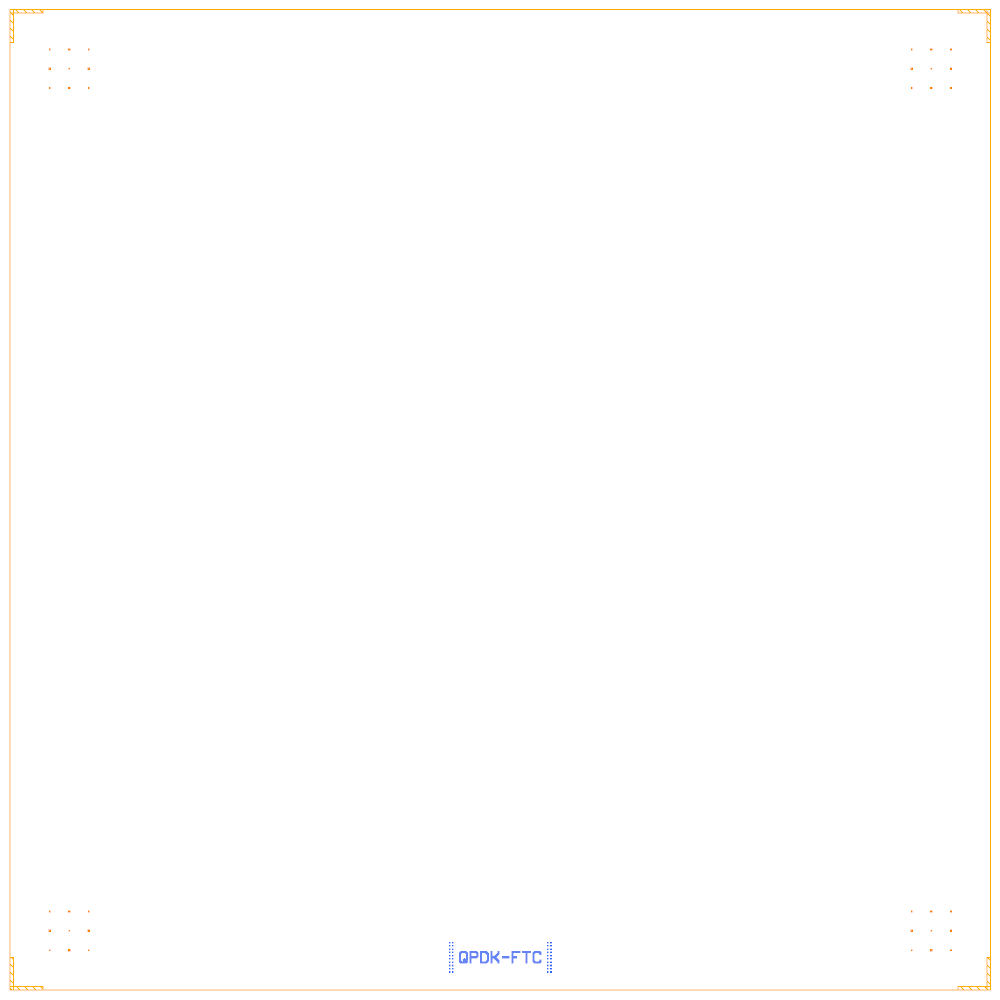

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/flipmon_test_chip/s1_die.png')

In [6]:
d = Designer("flipmon_test_chip", box=QP.die_box(4250, 6200), chip={"name_chip": "QPDK-FTC"}, live=LIVE)
layout_step(d, STEPS / "s1_die.png", size=(1000, 1000), width=400)

## Design 2 · Bond pads: the four launchers and the pad rule

QPDK's `launcher` (a 200 × 200 µm wire-bond pad on a 200/110 µm CPW, a 100 µm taper to the 10/6 µm line) is a
KQC-style `BondPad` here (`QP.LAUNCHER`). **PDK rule:** the outer etch edge of a pad sits `frame.pad_edge`
(100 µm) from the die edge. `edge="auto"` in `d.add` applies it: the pad keeps its position along the
nearest die edge (the source's launcher axis) and slides perpendicular to it until its etch ends 100 µm from
the edge. The lead routes to the circuit simply get longer; nothing else moves. The table shows each pad's
distance after the rule (✓ = 100 µm).
Launchers as in the qubit test chip: probeline in / out on the west edge, flux top / bottom.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| PAD_IN | `BondPad` | w | 100.0 | ✓ |
| PAD_OUT | `BondPad` | w | 100.0 | ✓ |
| PAD_FT | `BondPad` | n | 100.0 | ✓ |
| PAD_FB | `BondPad` | s | 100.0 | ✓ |

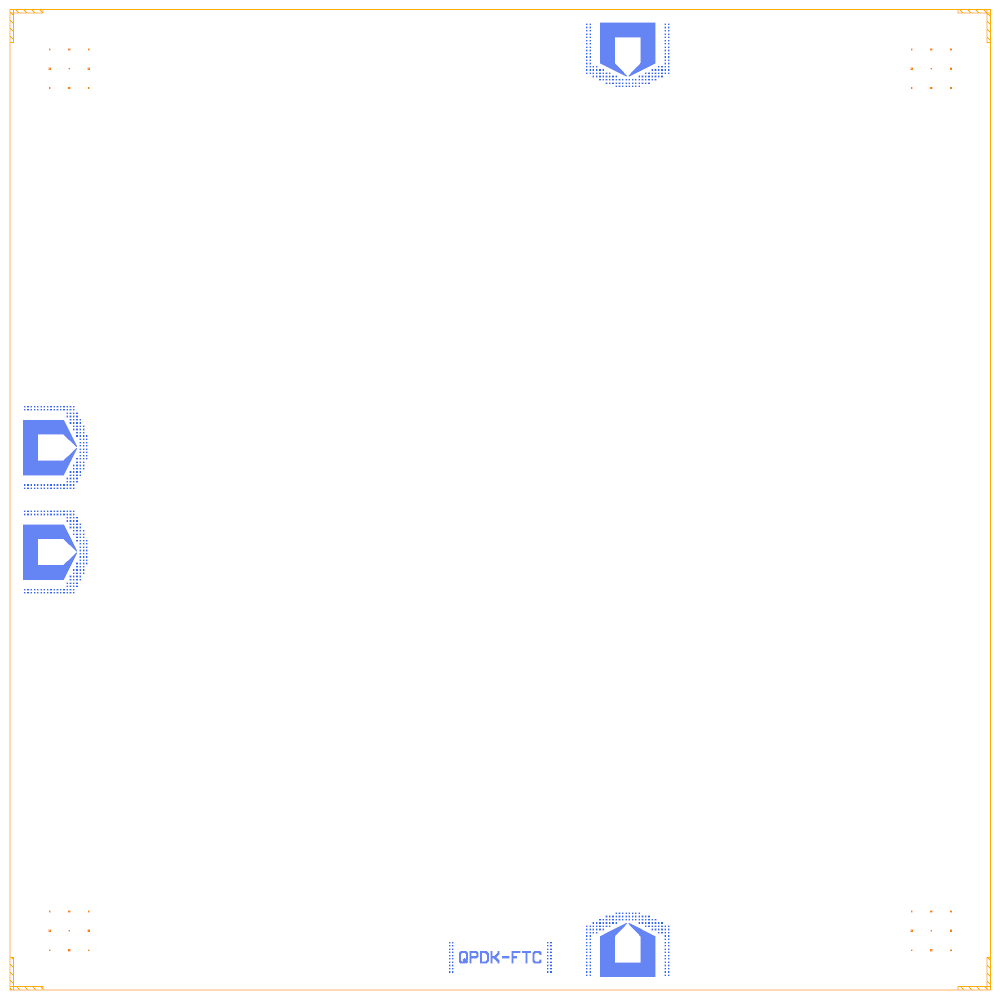

**On the chip so far:** 4 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 4 component(s) `PAD_IN`, `PAD_OUT`, `PAD_FT`, `PAD_FB`.

WindowsPath('build/snapshots/flipmon_test_chip/s2_pads.png')

In [7]:
with d.batch():
    pin = d.add("PAD_IN", "BondPad", at=(DX + QP.LAUNCHER_DEPTH, DY + 400), rot=270, edge="auto", **QP.LAUNCHER)
    pout = d.add("PAD_OUT", "BondPad", at=(DX + QP.LAUNCHER_DEPTH, DY - 400), rot=270, edge="auto", **QP.LAUNCHER)
    pft = d.add("PAD_FT", "BondPad", at=(DX + 3000, 6200 - QP.LAUNCHER_DEPTH), rot=180, edge="auto", **QP.LAUNCHER)
    pfb = d.add("PAD_FB", "BondPad", at=(DX + 3000, QP.LAUNCHER_DEPTH), rot=0, edge="auto", **QP.LAUNCHER)
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, STEPS / "s2_pads.png", size=(1000, 1000), width=400)

## Design 3 · Readout: the probeline and its two IDCs

The readout line needs no qubit, so it comes first. **Series IDCs** at the probeline input and output (`QP.IDC`, KQC
`FingerCapacitorSquare`, at source (800, ±400)). **Probeline:** launcher → C_IN → east, U-turn at x = 3815 µm
(source), west → C_OUT → launcher (r = 100 µm): every coupled section here is QPDK's automatic 800 µm, so the U-turn
sits 400 µm further east than on the qubit test chip. `FL_IN` / `FL_OUT` are the leads from the launchers to the
IDCs, `FL` the probeline the readouts hang on (Design 5).

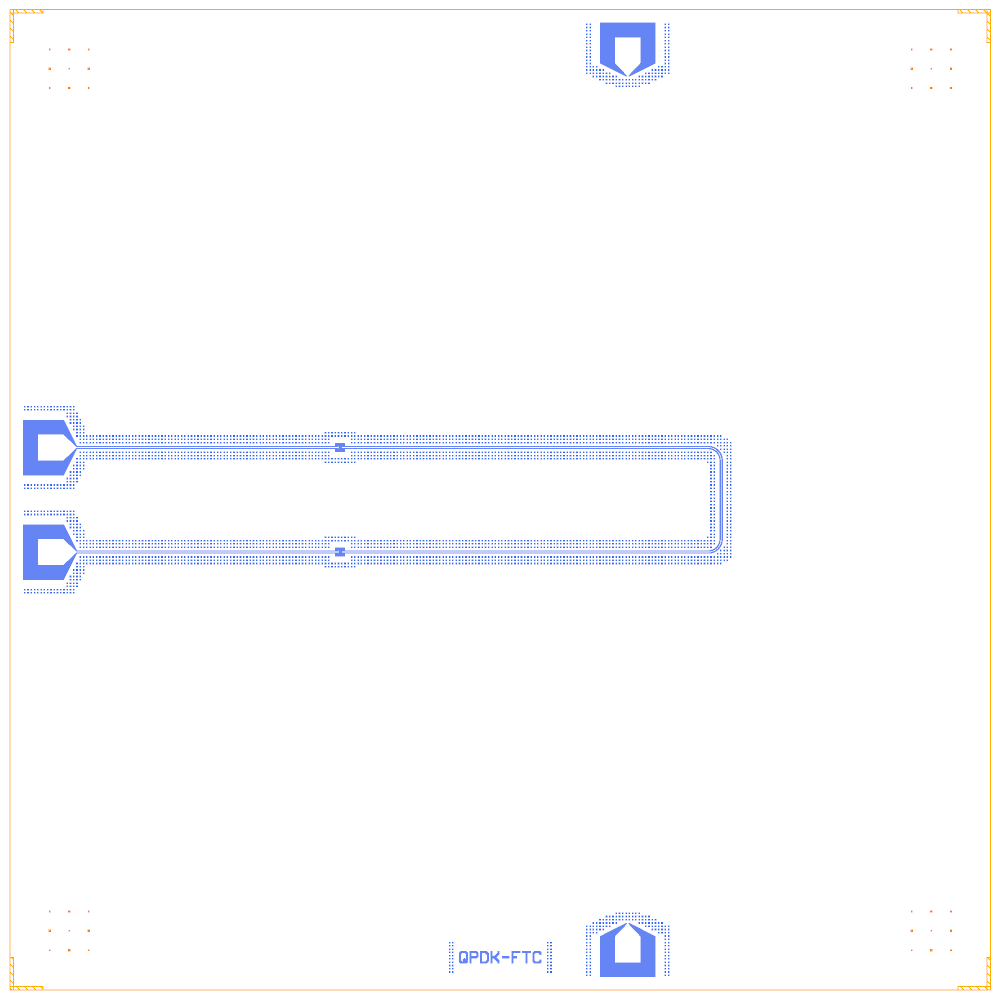

**On the chip so far:** 4 pads · 0 qubits · 2 other components · 3 routes · 0 declared couplings. **This step added** 2 component(s) `C_IN`, `C_OUT` and 3 route(s) `FL_IN`, `FL`, `FL_OUT`.

WindowsPath('build/snapshots/flipmon_test_chip/s3_readout_line.png')

In [8]:
with d.batch():
    cin = d.add("C_IN", "FingerCapacitorSquare", at=(DX + 800, DY + 400), **QP.IDC)
    cout = d.add("C_OUT", "FingerCapacitorSquare", at=(DX + 800, DY - 400), **QP.IDC)
    d.route("FL_IN", pin.a, cin.a, r=QP.CPW_R)
    fl = d.route("FL", cin.b, cout.b, nodes=[(3815, DY + 400), (3815, DY - 400)], r=QP.CPW_R)
    d.route("FL_OUT", cout.a, pout.a, r=QP.CPW_R)
layout_step(d, STEPS / "s3_readout_line.png", size=(1000, 1000), width=400)

## Design 4 · Qubit placement: four flipmons

**Four flipmons** (`Flipmon`, QPDK defaults with
`junction_position_rotation=180`): Q1 / Q2 with the plate south (rotation 270), Q3 / Q4 mirrored in the source
→ plate north (rotation 90). Ports: `coupler` (the readout plate), `squid_a` / `squid_b` (junction reference
points on the disc and ring edges; the junction is drawn inside the cell). Each carries the trilayer SQUID of the junction cell above (`JJ_PARAMS` on the cell, `JJ`
for the LOM). The first picture is the chip so far, the second zooms on Q1: the disc and the ring on the bottom chip,
the top-chip disc over them, the readout plate to the south.

<Flipmon Q1 ports=['coupler', 'squid_a', 'squid_b']>


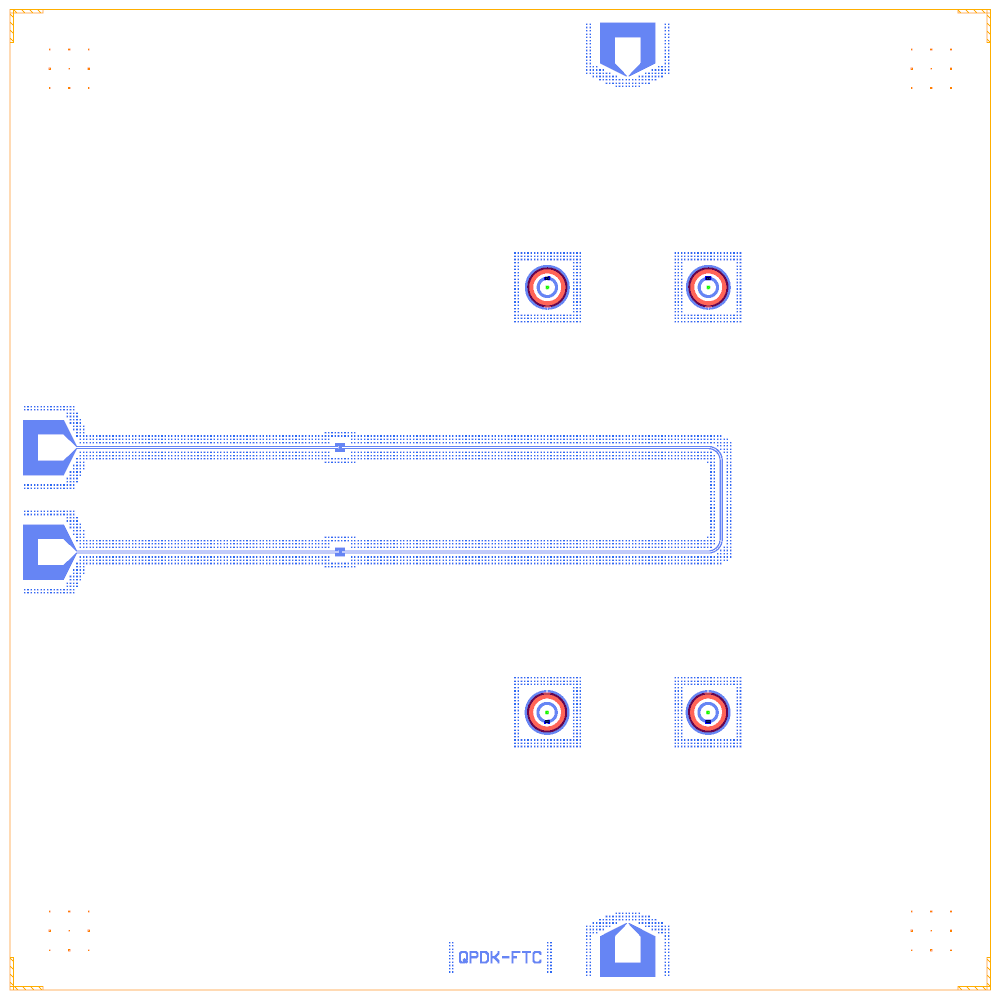

**On the chip so far:** 4 pads · 4 qubits · 2 other components · 3 routes · 0 declared couplings. **This step added** 4 component(s) `Q1`, `Q2`, `Q3`, `Q4`.

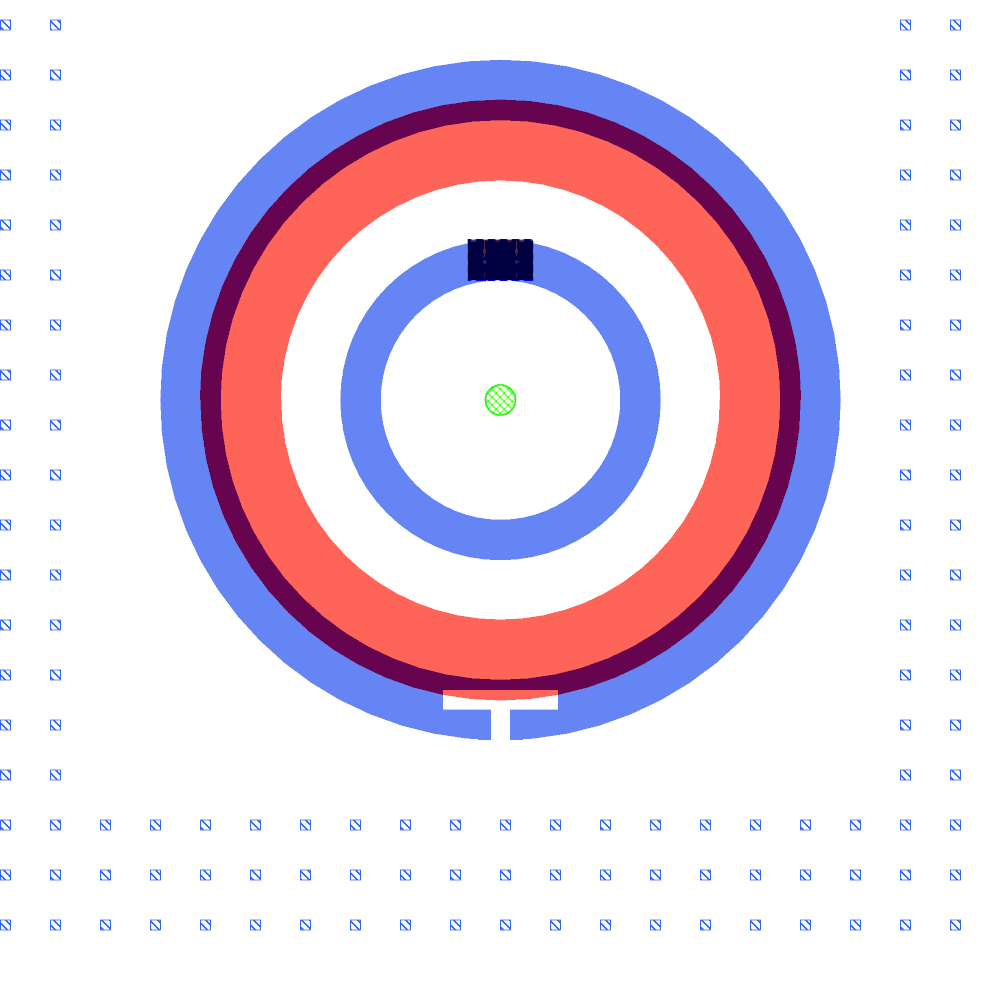

In [9]:
with d.batch():
    q = {n: d.add(n, "Flipmon", at=(DX + x, DY + y), rot=r, junction=JJ, **JJ_PARAMS, **FM)
         for n, x, y, r in (("Q1", 2385, 1625, 270), ("Q2", 3615, 1625, 270),
                            ("Q3", 3615, -1627.421, 90), ("Q4", 2385, -1628.351, 90))}
print(q["Q1"])
layout_step(d, STEPS / "s4_qubits.png", size=(1000, 1000), width=400)
qx, qy = d.data["instances"]["Q1"]["place"]["at"]
snap(d, STEPS / "s4_q1.png", box=(qx - 250, qy - 300, qx + 250, qy + 200), size=(1000, 1000), width=400);

## Design 5 · Readout: the four λ/2 readouts on the probeline

From each flipmon's plate, 900 µm west, a 7-turn meander (r = 50 µm), then the 800 µm coupled section centred 500 µm
west of the qubit, hanging on the probeline (`fl.hanger(s=..., length=800, ground_gap=4, end="open")`: `s` is the
arclength from the probeline's start at C_IN; open end → λ/2). The lengths are QPDK's 5000 / 4800 / 4600 / 4400 µm;
each route is QPDK's length − 13 µm (`PORT_EXTRA`: the `Flipmon` `coupler` port sits 13 µm beyond QPDK's plate
port).

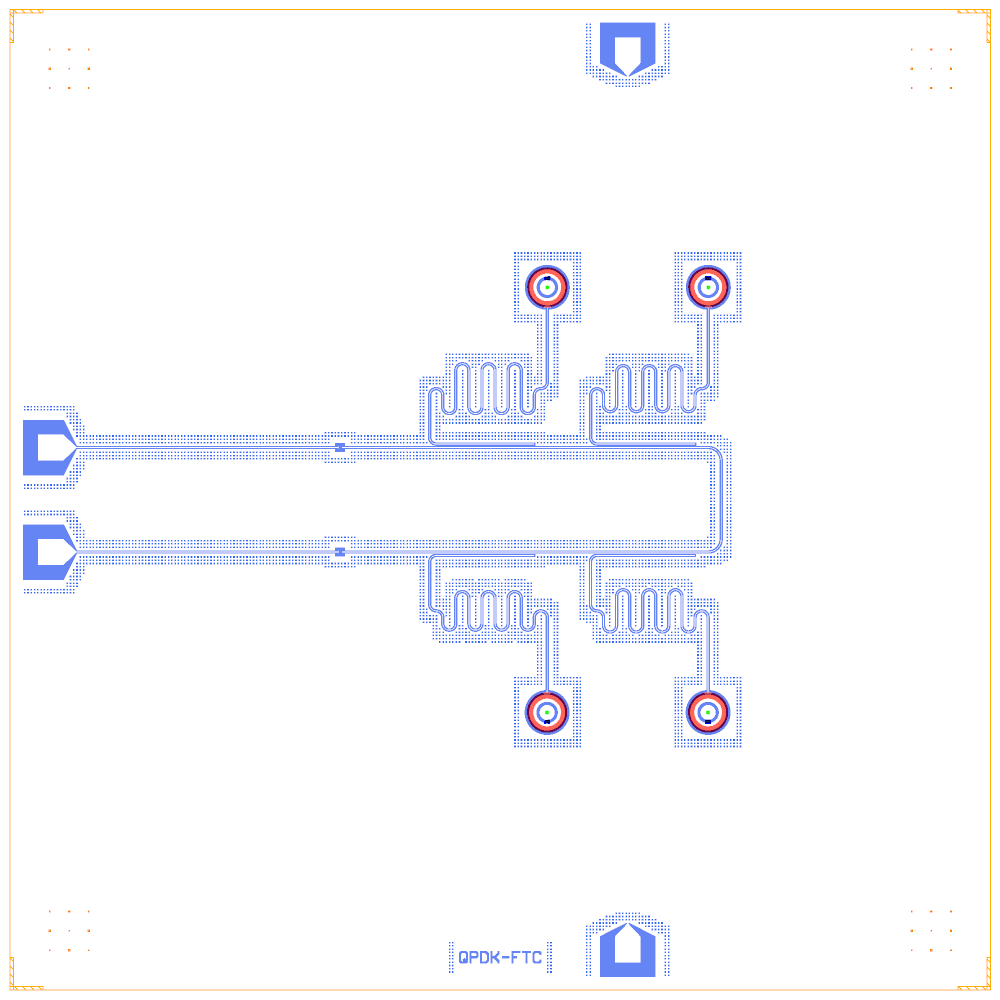

**On the chip so far:** 4 pads · 4 qubits · 2 other components · 7 routes · 0 declared couplings. **This step added** 4 route(s) `R1`, `R2`, `R3`, `R4`.

WindowsPath('build/snapshots/flipmon_test_chip/s5_readouts.png')

In [10]:
with d.batch():
    x0 = 936.5                                         # FL starts at C_IN.b
    west = (3815 - x0) + 800                           # FL arclength at the start of the west-bound leg
    for n, qn, total, y in (("R1", "Q1", 5000, 3950), ("R2", "Q2", 4800, 3950), ("R3", "Q3", 4600, 2250),
                            ("R4", "Q4", 4400, 2250)):
        xq = d.data["instances"][qn]["place"]["at"][0]
        xc = xq - 500                                  # coupled-section centre
        top = y > DY
        s = xc - x0 if top else west + 3815 - xc
        d.route(n, q[qn].coupler, fl.hanger(s=s, length=800, side="left", ground_gap=QP.HANGER_GROUND_GAP,
                                            direction="forward" if top else "backward", end="open"),
                meander=total - PORT_EXTRA, r=50, nodes=[(xq, y), (xq - 900, y)]).set(meanders=7)
layout_step(d, STEPS / "s5_readouts.png", size=(1000, 1000), width=400)

## Design 6 · Coupling: none on this chip

The four flipmons do not couple to each other: no bus, no coupler qubit, no `d.couple`. Each talks only to its own
λ/2 readout, and the four readouts share the probeline (four lengths, so four frequencies).

## Design 7 · Routing: the two flux lines

**Flux lines** from the top / bottom launchers to an open end between the qubit pairs (`Designer.free_end(...,
term=6)`, as on the qubit test chip). They end beside the qubits, not on a SQUID, so the LOM has no flux control for
them (Check 2).

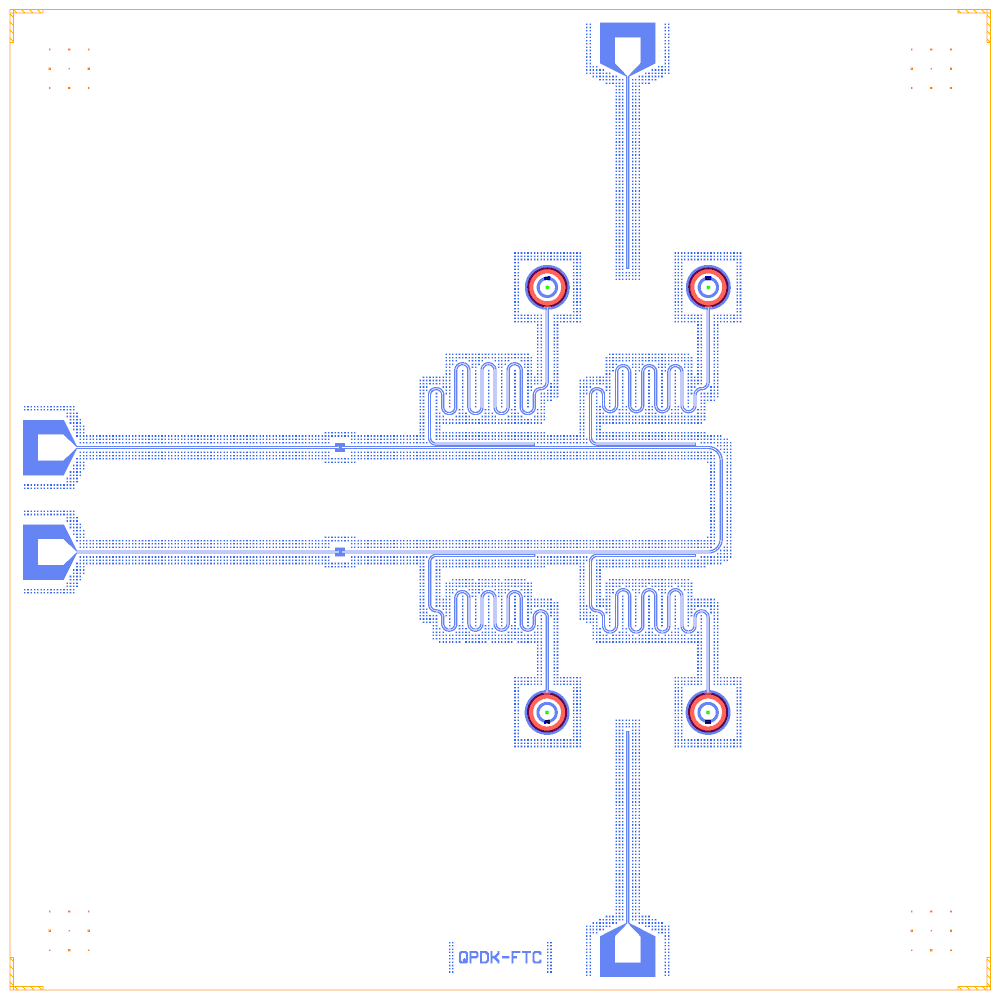

**On the chip so far:** 4 pads · 4 qubits · 2 other components · 9 routes · 0 declared couplings. **This step added** 2 route(s) `FLUX_T`, `FLUX_B`.

{'FL_IN': 1978.5, 'FL': 6471.2, 'FL_OUT': 1978.5, 'R1': 4987.0, 'R2': 4787.0, 'R3': 4587.0, 'R4': 4387.0, 'FLUX_T': 1465.0, 'FLUX_B': 1465.0}


In [11]:
with d.batch():
    d.route("FLUX_T", pft.a, Designer.free_end((DX + 3000, DY + 1775), dir=90, term=6), r=QP.CPW_R)
    d.route("FLUX_B", pfb.a, Designer.free_end((DX + 3000, DY - 1775), dir=270, term=6), r=QP.CPW_R)
layout_step(d, STEPS / "s7_flux.png", size=(1000, 1000), width=400)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

## Design 8 · The whole chip: sim groups, the centring, save

**Sim groups** say what a FEM job cuts out of the chip: one per qubit with its readout and the probeline (Q3D
C-matrix + eigenmode/EPR, 150 µm margin).

**Centring.** `pdk_report` measures the content centre over everything placed, pads included, so the whole layout is
centred, not only the circuit. The probeline pads sit 100 µm (`frame.pad_edge`) from the west die edge
(`edge="auto"`), which fixes the west side of the content, so `QP.center_content` shifts the circuit east until the
content box's centre is the die centre (to 0.5 µm). Each pad keeps its 100 µm and slides only along its edge: the
west pads follow the shift in y, the top / bottom flux pads in x (their edge is fixed first, so a pad that slides far
along an edge does not switch to another one). Here the circuit moves **+1890 µm** in x from the source frame (the circuit-only centring
of earlier versions stopped 2139 µm short of that). The circuit's east side (the Q2 / Q3 pockets) then sits exactly on the
design-area margin, 100 µm from the east die edge: the DRC raises no `frame_margin` / `frame_keepout` warning and the
PDK cheese band still fits (its holes stop 10 µm inside the margin). The price: the probeline leads from the pads to
the IDCs are 3868.5 µm long (were 1729.3 µm); the readouts, the probeline and the qubits are unchanged, and so is the LOM (the
leads are outside the sim groups).

**Save.** The JSON is the deliverable (DRC, LOM, FEM and `qcc` read it). `save_design` writes it and compares it
with the file it replaces (the previous run's): the segments above changed how the chip is built, not the chip, so it
should say *same design*. The file keeps the previous key order, so `git diff` stays empty.

centring shift of the circuit (µm): (1890.0, 0.0)


lead lengths (µm): {'FL_IN': 3868.5, 'FL_OUT': 3868.5, 'FLUX_T': 1465.0, 'FLUX_B': 1465.0}


**Same design as before:** `examples/designs/qpdk/flipmon_test_chip.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer flipmon_test_chip: 10 instances, 9 routes, live=False> → examples\designs\qpdk\flipmon_test_chip.json


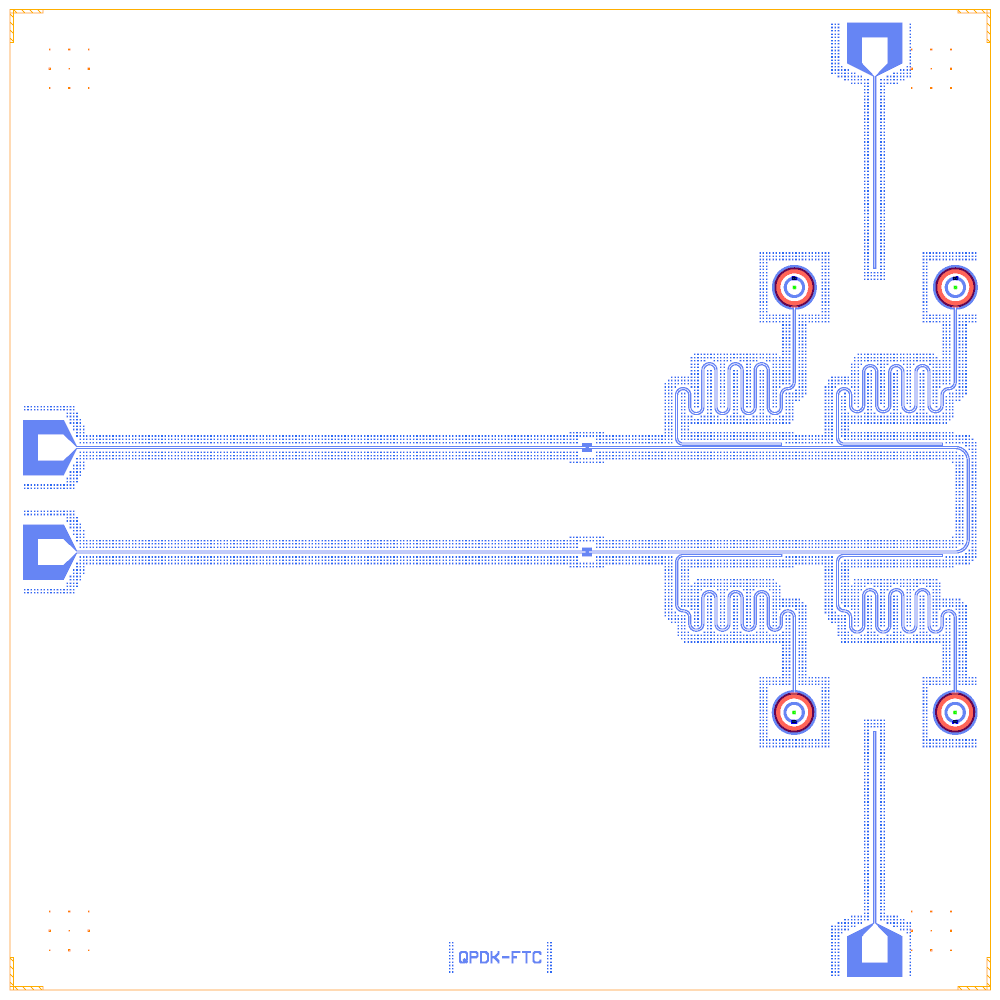

**On the chip so far:** 4 pads · 4 qubits · 2 other components · 9 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/flipmon_test_chip/s8_chip.png')

In [12]:
for i in range(1, 5):
    d.sim_group(f"Q{i}R{i}", [f"Q{i}", f"R{i}", "FL"], margin_um=150)
SHIFT = QP.center_content(d)                  # the whole layout (pads included) centred, pads stay on their edges
print("centring shift of the circuit (µm):", SHIFT)
rebuild(d)
print("lead lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items() if k in ("FL_IN", "FL_OUT", "FLUX_T", "FLUX_B")})
DESIGN, same = save_design(d, OUT / "flipmon_test_chip.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, STEPS / "s8_chip.png", size=(1000, 1000), width=400)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends,
metal outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to
read. **PDK design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`,
`pdk_claw`): flagged, never enforced — the rebuild keeps the source's choices. `pdk_report` adds the
cheese source, the centring (of everything, pads included: it reads (+0, +0) µm after Design 8's `QP.center_content`)
and the junction types.
Expected here (from the v1 run): eight `dangling_port` warnings (the `Flipmon` `squid_a` / `squid_b` reference points; the junction is drawn
inside the cell) and no PDK design warning (SQUID R_n 45 kΩ — the parallel R_n of its two junctions — inside
the window; pads at 100 µm).

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit
nodes, routes join nodes (or become transmission-line resonators), pads are 50 Ω ports, flux / gate lines
are controls. The first table lists the nodes and the FEM nets that form each one, the second the
branches with their component estimates; the last one maps a few ports to their nodes.
The `Flipmon` model: the inner disc + the top-chip disc form one island node, the ring is a second node, the
SQUID joins them, both have C to ground, and the plate is a coupler node. Each readout is a λ/2 `TLres` from the
plate node with a `HANGER` κ element to the probeline node.

In [ ]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(('Q1.', 'R1',)))))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Each group holds one qubit, its λ/2 readout and the probeline (QuCat normal modes and κ, then QuTiP f_q, α, f_r,
χ). The source states no targets; f_q follows from the PDK SQUID and the rough flip-chip capacitance (assumed
8 µm gap): ≈ 5.4 GHz expected (the earlier 12 nH stand-in gave 4.2 GHz; the v1 run: 5.385 GHz for all four, the readouts at 12.3–14.0 GHz).

In [ ]:
groups = {f"Q{i}R{i}": [f"Q{i}", f"R{i}", "FL"] for i in range(1, 5)}
res = simulate_groups(d, groups)
display(Markdown(groups_md(res)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group (QuCat; circles are qubits, squares
resonators; filled markers are the QuTiP dressed values), (b) the dispersive shift |χ| of each readout. From the v1
run: the four flipmons sit together at 5.39 GHz, the readouts 7.0–8.6 GHz above them, and the small plate (C_g ≈ 6 fF)
gives |χ| of only ≈ 0.04 MHz.

In [ ]:
plot_lom(res, STEPS / "lom.png", title="flipmon_test_chip: LOM per qubit / readout pair")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The junction is the qubit's main knob: size Q1's SQUID for L_J = 9 nH instead of 6.73 nH (narrower fingers,
R_n ≈ 60 kΩ in parallel — outside the PDK window, so `pdk_rn` would flag it). f_q drops roughly as
1/√L_J (≈ −14 %) and |α| barely moves. Done on a copy (`design_copy`), so the design keeps the PDK nominal SQUID.

In [ ]:
JJ_PARAMS_9, JJ_9 = QP.trilayer_junction("Flipmon", lj_nH=9.0, squid=True)
d2 = design_copy(DESIGN)
d2["Q1"].set(junction=JJ_9, **JJ_PARAMS_9)
after = simulate_groups(d2, {"Q1R1": groups["Q1R1"]})
display(Markdown("**Q1 SQUID: L_J 6.73 → 9 nH**\n\n" + params_delta_md({"Q1R1": res["Q1R1"]}, after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/qpdk/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

Per qubit / readout pair a Q3D C-matrix job and an eigenmode / EPR job. **Export limits** (reported to components /
lead): an earlier export found no metal edge at the `Flipmon` junction port (its reference points land inside the
60–80 µm disc–ring gap), logged "Unable to create polygon for port 1" and put the disc and the ring on one
excitation; the v1 run's job table lists both `Q<k>.island1` and `Q<k>.island2`, so read the table (and the export
log) below before trusting a disc–ring C. The stack is single-face, so the top-chip disc (face 2b1) is not in the
job (the export notes say so): treat these jobs as bottom-chip geometry, not as a flip-chip C-matrix.
Each sim group is cut out of the chip with its margin; every line leaving the box ends in a port, a
junction is a lumped port, and the cheese is never exported (simulation exports have none). The table
lists each job's ports and C-matrix nets (named after the islands, couplers and routes, so a result maps
back onto the LOM nodes). `FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. CLI: `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/qpdk/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix: one job per sim group
jobs_eig = export_sims(DESIGN, analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed
unless `airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says
what the export left out (this chip has no airbridges, so both settings give the same geometry).

In [ ]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "Q1R1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitance of each component group, `Q1R1` … `Q4R4`, as named nets. Read the export limits above first: the
top-chip disc is not in the job, and check that the disc and the ring come out as two nets, so these matrices are
the bottom chip's, not the flipmon's full C_Σ. `fem_stage` solves each job with `RUN_FEM`, else loads its kept
results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same four boxes in HFSS eigenmode: the SQUID is a lumped L_J ‖ C_J sheet, every line the box cuts ends in 50 Ω,
so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the
junction's energy participation p_J into dressed frequencies, α and χ. The same limits hold: one face only, so the
qubit mode is the bottom chip's alone.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box: S21 along the probeline, where R1's open coupled section
shows up as a notch. The library cannot hand the solved eigenmode **mesh** itself to a driven setup (no such option
yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim group and box, the eigenmode job's mesh
seeds, the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and
a fast sweep around it. Q1R1 is the example; the other three groups go the same way.

In [ ]:
f_r1 = res["Q1R1"].params.get("R1.f_GHz")                 # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q1R1", jobs_eig["Q1R1"][0], keep_eig["Q1R1"], f_guess=f_r1)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q1R1"]:
    display(Markdown(driven_md(keep_drv["Q1R1"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: a qubit; ≈ 0: a readout), with the LOM's frequencies of the same
components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
lom_f = {}
for i in range(1, 5):
    p = res[f"Q{i}R{i}"].params
    lom_f.update({f"Q{i}": p.get(f"Q{i}.f_q_GHz"), f"R{i}": p.get(f"R{i}.f_GHz")})
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own SQUID participates in most, the readout's
the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr terms,
κ = f/Q of the 50 Ω-terminated box. The driven run adds R1's S21 notch.

In [ ]:
fem_values = {}
for i in range(1, 5):
    keep = keep_eig.get(f"Q{i}R{i}")
    if keep:
        fem_values[f"Q{i}"] = epr_values(keep, {f"Q{i}": f"R{i}"}, {f"R{i}": lom_f[f"R{i}"]})
if keep_drv["Q1R1"]:
    fem_values.setdefault("Q1", {}).update({f"driven {k}": v for k, v in
                                            driven_values(keep_drv["Q1R1"], "R1", f_r1).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} |" for vals in fem_values.values() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α, f_r, χ and κ of each flipmon and "
          "its readout from pyEPR, and the S21 notch of R1.")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. With the single-face export, expect the FEM
qubit to sit above the LOM's (no top-chip disc: less C_Σ).

In [ ]:
from quantcore_circuits.circuit.fill import fill

rows = []
for i in range(1, 5):
    g = f"Q{i}R{i}"
    est = res[g].params
    keys = [f"Q{i}.f_q_GHz", f"Q{i}.alpha_MHz", f"R{i}.f_GHz", f"R{i}.chi_MHz", f"R{i}.kappa_MHz"]
    if keep_q3d.get(g):
        on_fem = simulate(fill(d.lom(select=groups[g]).model, DESIGN, keep_q3d[g]), max_modes=2).params
        rows += [(key, est.get(key), on_fem.get(key), "LOM on the Q3D C-matrix") for key in keys]
    for key in keys:
        if key in fem_values.get(f"Q{i}", {}):
            rows.append((key, est.get(key), fem_values[f"Q{i}"][key], "eigenmode + pyEPR"))
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The source states no targets, so this notebook sets one as an exercise: **Q1 at 5.6 GHz**, ≈ 0.2 GHz above where the
LOM puts it (from the v1 run: 5.385 GHz). It is reachable inside the PDK junction window: the SQUID's L_J goes from
6.73 nH to ≈ 6.2 nH, R_n ≈ 42 kΩ (`pdk_lj_bounds` keeps the feedback within 40–50 kΩ; the window allows ≈ 5.1–5.7 GHz
here). The readouts are not targeted (they sit 7–8.6 GHz above the qubits by the source's lengths).

The targets go on a copy (`target_copy` → `build/flipmon_test_chip_target.json`), so the design file keeps its own
(none). `loop.analyse` runs the estimators on every qubit–readout pair — on the Q3D values where a solve was kept (see
the export limits) — and picks one value per quantity (the consensus). `loop.feedback` anchors a surrogate on that
point and proposes the knobs that put the target inside its tolerance (f_q ± 20 MHz); the proposal is written as
revision 1, built and netlist-checked. The revision changes the LOM's L_J; the drawn SQUID follows only when its
`junction_params` are set too, as LOM 3 does with `QP.trilayer_junction("Flipmon", lj_nH=..., squid=True)`.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"Q1": {"f_q_GHz": 5.6}}               # the exercise target (GHz); add more here
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/flipmon_test_chip/revisions/`). Without
`RUN_FEM` each revision is judged on the LOM. With `RUN_FEM = True` each revision's Q1R1 Q3D job (the targeted pair)
is exported and solved first (`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The
table shows each iteration's value against the target and the knob it moved; the plot the residual in tolerances (on
target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q1R1 Q3D job, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ("Q1R1",)}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `flipmon_test_chip.json` (saved in Design 8) is the whole design: `qcc build
examples/designs/qpdk/flipmon_test_chip.json` rebuilds `build/flipmon_test_chip.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the
filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers
2/0 + 4/0 and spacer 50/0 with the 51–53/0 dose gradient, flip-chip 800+/0 where used, and the frame
(100/0, 1000/0, 1001/0).
The flip-chip top face exports to 800/0 (etch), 801/0 (indium bump) and 802/0 (UBM). The cheese source is
`build`: the PDK band on the bottom chip (the source has none), at least 4 µm clear of 3/0.
Corner rounding (fab only) is skipped unless `FULL_FAB`; `qcc mask examples/designs/qpdk/flipmon_test_chip.json`
writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The full die (QPDK's render of the *filled* flipmon variant is shown last); qubit Q1 with its readout plate (both
faces); its junction; the R1 coupled section's open end; the top flux-line end; the die frame's south-west
corner; and Q1 in the **fab view** (the mask from Fab 1: 1/0 with the PDK cheese band, 3/0, the trilayer
layers, the 800/0 face). Boxes are the source positions + the centring shift. (Layout snapshots: the chip
boundary 100/0 is drawn as an outline and the cheese band is visible; the fab view shows the mask itself.)

In [ ]:
SX, SY = SHIFT


def box(x0, y0, x1, y1):                         # a source-frame box, moved with the centring shift
    return (x0 + SX, y0 + SY, x1 + SX, y1 + SY)


show_snapshot(d, OUT / "flipmon_test_chip.png", size=(1600, 1600))
qx, qy = d.data["instances"]["Q1"]["place"]["at"]
show_snapshot(d, OUT / "flipmon_test_chip_q1.png", box=(qx - 250, qy - 300, qx + 250, qy + 200), size=(1000, 1000), width=400)
show_snapshot(d, OUT / "flipmon_test_chip_squid.png", box=(qx - 25, qy + 50, qx + 25, qy + 95), size=(1000, 900), width=300)
show_snapshot(d, OUT / "flipmon_test_chip_coupler.png", box=box(2300, 3440, 2480, 3600), width=360)
show_snapshot(d, OUT / "flipmon_test_chip_flux.png", box=box(2900, 4500, 3300, 5000), width=360)
show_snapshot(d, OUT / "flipmon_test_chip_frame.png", box=(-1625, -650, -725, 250), size=(900, 900), width=300)
snap_file(Path("build") / "flipmon_test_chip_fab.oas", OUT / "flipmon_test_chip_fab_q1.png",
          box=(qx - 300, qy - 350, qx + 300, qy + 250), size=(1000, 1000), width=400);

**The original.** gdsfactory is not installed in this environment, so the source is not rebuilt here; QPDK's own
render (of the filled flipmon variant, the only image QPDK publishes for this chip) is shown from the local
clone when present.

In [ ]:
SRC_IMG = Path("build/external/quantum-rf-pdk/docs/_static/images") / "flipmon_test_chip.png"   # QPDK's own render (MIT), from the local clone if present
if SRC_IMG.exists():
    display(Image(filename=str(SRC_IMG), width=420))
else:
    print("QPDK image not in this checkout: "
          "https://github.com/gdsfactory/quantum-rf-pdk/blob/main/docs/_static/images/flipmon_test_chip.png")

## Summary

| | |
|---|---|
| **matches the source** | the qubit test chip's netlist with QPDK's flipmon (both faces, bump, plate), readout lengths 5000–4400 µm with 800 µm coupled sections (λ/2, open), the U-turn at 3815 µm, IDCs, flux lines, launcher size |
| **differs (PDK)** | 7.5 mm Quantcore die and frame (bottom chip only); pads 100 µm from the die edge; the whole layout centred (circuit +1890 µm in x, pads included; probeline leads 3869 µm, the circuit's east side 100 µm from the east die edge); sapphire; trilayer SQUIDs across the disc–ring gap (LOM f_q ≈ 5.4 GHz, from the v1 run); the PDK cheese band |
| **estimated** | the flip-chip capacitance (assumed 8 µm gap); the FEM jobs are single-face geometry exports |
| **PDK design warnings** | none |
| layout | built in eight segments (die, launchers, probeline and IDCs, flipmons, readouts, no coupling, flux lines, the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (Q1 5.6 GHz): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells; the FEM jobs are single-face exports (no top-chip disc; check that the disc and the ring are two nets) |